# Calibration de caméra avec un damier (OpenCV), version 2

Corrections par rapport à la v1 :
- lecture des photos **sans appliquer l'orientation EXIF** (portrait et paysage ont alors la même taille de capteur) ;
- détection du damier dans les **deux orientations** (COLS×ROWS et ROWS×COLS), avec plusieurs échelles puis `findChessboardCornersSB` en secours ;
- calibration avec `CALIB_FIX_K3` et `CALIB_ZERO_TANGENT_DIST` (option) pour éviter une distorsion irréaliste ;
- correction de distorsion sans bandes noires (`alpha = 0`).

`COLS` et `ROWS` = nombre de **coins intérieurs**.

## 0. Imports et paramètres

In [ ]:
import glob
import os

import cv2
import numpy as np
import matplotlib.pyplot as plt

# ---- À ADAPTER ----
IMAGES_DIR = "images"
COLS, ROWS = 8, 5        # coins intérieurs (horizontal, vertical)
SQUARE_MM = 20.0         # taille réelle d'un carré en mm
MAX_DIM = 1600           # taille réduite pour la détection rapide
FIX_K3 = True            # True = plus stable (recommandé pour un téléphone)
ZERO_TANGENT = True      # True = ignore la distorsion tangentielle p1, p2
# -------------------

OUT_CORNERS = "output/corners"
OUT_RESULTS = "results"
os.makedirs(OUT_CORNERS, exist_ok=True)
os.makedirs(OUT_RESULTS, exist_ok=True)

PATTERN = (COLS, ROWS)
print("OpenCV", cv2.__version__)

OpenCV 5.0.0


## 1. Points 3D du damier (`objp`)
Une fonction, car le damier peut apparaître tourné de 90° (alors détecté comme ROWS×COLS). Chaque vue a son propre repère du damier, ce qui est valide pour la calibration.

In [2]:
def make_objp(cols, rows, square):
    objp = np.zeros((rows * cols, 3), np.float32)
    objp[:, :2] = np.mgrid[0:cols, 0:rows].T.reshape(-1, 2)
    return objp * square  # en mm

objp = make_objp(COLS, ROWS, SQUARE_MM)
print(objp.shape)
print(objp[:4])

(40, 3)
[[ 0.  0.  0.]
 [20.  0.  0.]
 [40.  0.  0.]
 [60.  0.  0.]]


## 2. Détection des coins

In [3]:
CRIT = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)


def list_images(folder):
    files = []
    for e in ("jpg", "jpeg", "png", "bmp"):
        files += glob.glob(os.path.join(folder, f"*.{e}"))
        files += glob.glob(os.path.join(folder, f"*.{e.upper()}"))
    return sorted(set(files))


def _resize(gray, max_dim):
    h, w = gray.shape
    if max_dim and max(h, w) > max_dim:
        s = max_dim / max(h, w)
        return cv2.resize(gray, None, fx=s, fy=s, interpolation=cv2.INTER_AREA), s
    return gray, 1.0


def detect_classic(gray, pattern, max_dim):
    small, s = _resize(gray, max_dim)
    flags = cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE
    ok, c = cv2.findChessboardCorners(small, pattern, flags)
    if not ok:
        return False, None
    c = (c / s).astype(np.float32)
    c = cv2.cornerSubPix(gray, c, (11, 11), (-1, -1), CRIT)
    return True, c


def detect_sb(gray, pattern, max_dim=2000):
    small, s = _resize(gray, max_dim)
    flags = cv2.CALIB_CB_EXHAUSTIVE + cv2.CALIB_CB_ACCURACY
    try:
        ok, c = cv2.findChessboardCornersSB(small, pattern, flags)
    except cv2.error:
        return False, None
    if not ok:
        return False, None
    return True, (c / s).astype(np.float32)


def detect(gray):
    """Essaie les deux orientations du motif. Retourne (ok, corners, pattern_utilisé)."""
    patterns = [PATTERN, PATTERN[::-1]]
    for pat in patterns:                      # 1) méthode classique, image réduite puis pleine
        for md_ in (MAX_DIM, 0):
            ok, c = detect_classic(gray, pat, md_)
            if ok:
                return True, c, pat
    for pat in patterns:                      # 2) secours : méthode SB (plus robuste)
        ok, c = detect_sb(gray, pat)
        if ok:
            return True, c, pat
    return False, None, None


files = list_images(IMAGES_DIR)
print(f"{len(files)} images trouvées dans '{IMAGES_DIR}'")

# IGNORE_ORIENTATION : on garde l'orientation brute du capteur (même taille pour toutes)
READ_FLAGS = cv2.IMREAD_COLOR | cv2.IMREAD_IGNORE_ORIENTATION

objpoints, imgpoints, used, rejected, previews = [], [], [], [], []
image_size = None  # (largeur, hauteur)

for path in files:
    name = os.path.basename(path)
    img = cv2.imread(path, READ_FLAGS)
    if img is None:
        print(f"[ERREUR] lecture impossible : {name}")
        rejected.append(name)
        continue

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    size = (gray.shape[1], gray.shape[0])
    if image_size is None:
        image_size = size
    elif size != image_size:
        print(f"[IGNORÉE] {name} : taille {size} différente de {image_size}")
        rejected.append(name)
        continue

    ok, corners, pat = detect(gray)
    if not ok:
        print(f"[NON DÉTECTÉ] {name}")
        rejected.append(name)
        continue

    objpoints.append(make_objp(pat[0], pat[1], SQUARE_MM))
    imgpoints.append(corners)
    used.append(name)

    vis = img.copy()
    cv2.drawChessboardCorners(vis, pat, corners, True)
    cv2.imwrite(os.path.join(OUT_CORNERS, f"corners_{name}"), vis)
    previews.append((name, vis))
    tag = "" if pat == PATTERN else f" (motif tourné {pat[0]}x{pat[1]})"
    print(f"[OK] {name}{tag}")

print(f"\nImages utilisées : {len(used)} / {len(files)}  | taille : {image_size}")
if 0 < len(used) < 10:
    print("ATTENTION : moins de 10 images valides, prenez plus de photos variées.")

33 images trouvées dans 'images'
[NON DÉTECTÉ] IMG20261104234334.jpg
[NON DÉTECTÉ] IMG20261104234342.jpg
[NON DÉTECTÉ] IMG20261104234349.jpg
[NON DÉTECTÉ] IMG20261104234353.jpg
[IGNORÉE] IMG20261104234407.jpg : taille (3072, 4080) différente de (4080, 3072)
[IGNORÉE] IMG20261104234409.jpg : taille (3072, 4080) différente de (4080, 3072)
[IGNORÉE] IMG20261104234518.jpg : taille (3072, 4080) différente de (4080, 3072)
[IGNORÉE] IMG20261104234521.jpg : taille (3072, 4080) différente de (4080, 3072)
[OK] IMG20261104234523.jpg
[NON DÉTECTÉ] IMG20261104234526.jpg
[IGNORÉE] IMG20261104234532.jpg : taille (3072, 4080) différente de (4080, 3072)
[IGNORÉE] IMG20261104234533.jpg : taille (3072, 4080) différente de (4080, 3072)
[IGNORÉE] IMG20261104234536.jpg : taille (3072, 4080) différente de (4080, 3072)
[IGNORÉE] IMG20261104234538.jpg : taille (3072, 4080) différente de (4080, 3072)
[IGNORÉE] IMG20261104234540.jpg : taille (3072, 4080) différente de (4080, 3072)
[IGNORÉE] IMG20261104234543.jpg

### Aperçu des détections

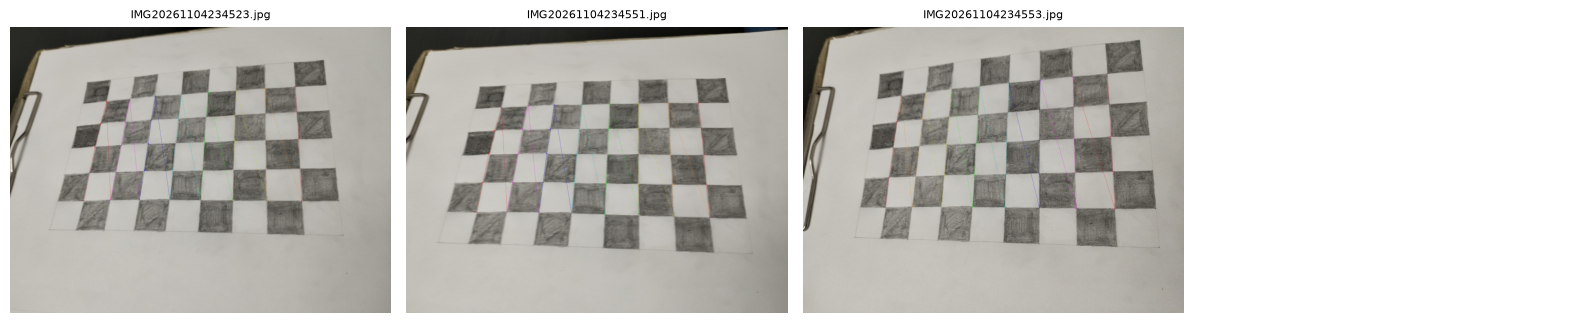

In [4]:
def show_grid(items, ncols=4, max_items=12):
    items = items[:max_items]
    if not items:
        print("Rien à afficher.")
        return
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.2 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, (name, im) in zip(axes, items):
        sm, _ = (cv2.resize(im, None, fx=0.2, fy=0.2, interpolation=cv2.INTER_AREA), 0.2)
        ax.imshow(cv2.cvtColor(sm, cv2.COLOR_BGR2RGB))
        ax.set_title(name, fontsize=8)
    plt.tight_layout()
    plt.show()

show_grid(previews)

### Diagnostic des images non détectées (optionnel)
Affiche quelques images rejetées pour comprendre pourquoi (flou, damier coupé, trop incliné, reflet...).

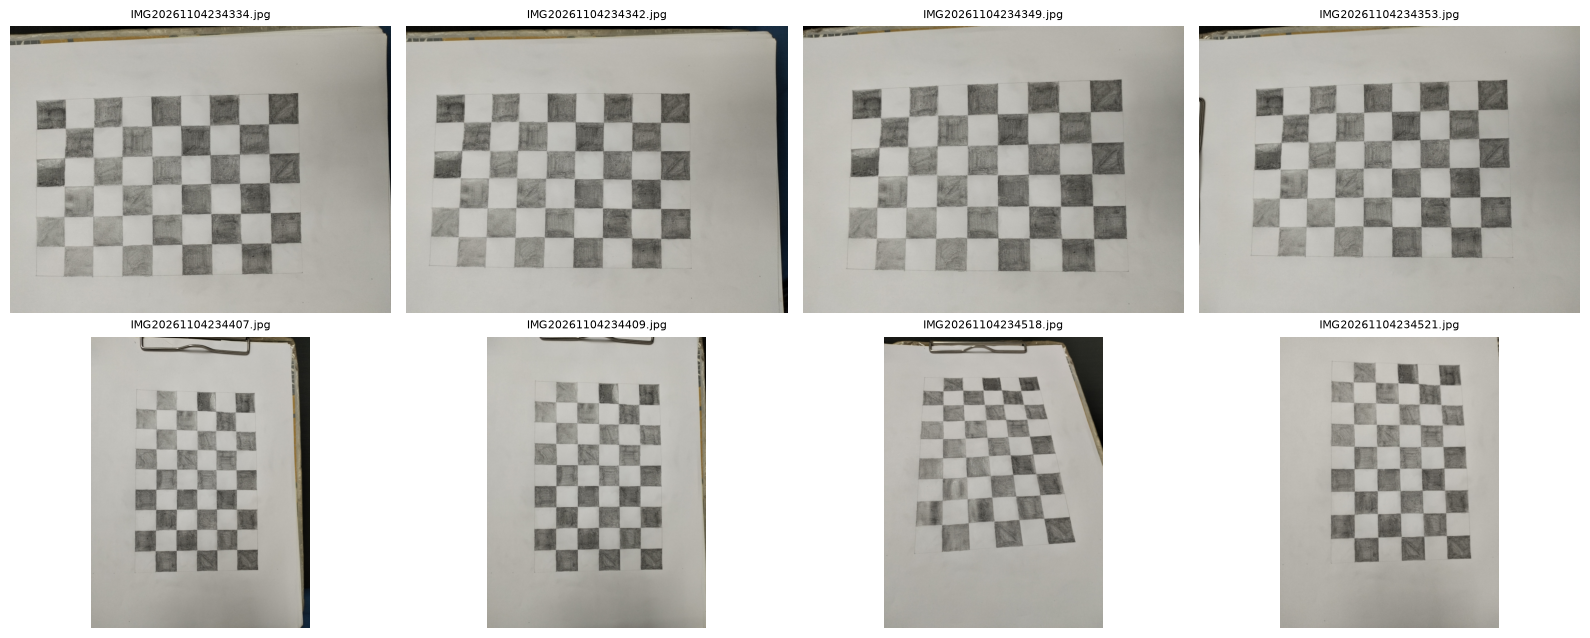

In [5]:
rej_show = []
for n in rejected[:8]:
    im = cv2.imread(os.path.join(IMAGES_DIR, n), READ_FLAGS)
    if im is not None:
        rej_show.append((n, im))
show_grid(rej_show)

## 3. Calibration (`cv2.calibrateCamera`)

In [6]:
assert len(used) >= 3, "Pas assez d'images valides pour calibrer."

flags = 0
if FIX_K3:
    flags |= cv2.CALIB_FIX_K3
if ZERO_TANGENT:
    flags |= cv2.CALIB_ZERO_TANGENT_DIST

rms, K, dist, rvecs, tvecs = cv2.calibrateCamera(
    objpoints, imgpoints, image_size, None, None, flags=flags
)

print(f"Taille image : {image_size[0]} x {image_size[1]} px")
print(f"RMS (calibrateCamera) : {rms:.4f} px\n")
print("Matrice intrinsèque K :")
print(np.array2string(K, precision=3, suppress_small=True))
print(f"\nfx = {K[0,0]:.2f} px   fy = {K[1,1]:.2f} px")
print(f"cx = {K[0,2]:.2f} px   cy = {K[1,2]:.2f} px")
print("\nDistorsion (k1, k2, p1, p2, k3) :")
print(dist.ravel())

Taille image : 4080 x 3072 px
RMS (calibrateCamera) : 6.5938 px

Matrice intrinsèque K :
[[3313.218    0.    2047.833]
 [   0.    3323.129 1532.631]
 [   0.       0.       1.   ]]

fx = 3313.22 px   fy = 3323.13 px
cx = 2047.83 px   cy = 1532.63 px

Distorsion (k1, k2, p1, p2, k3) :
[ 0.0562536  -0.39010759  0.          0.          0.        ]


## 4. Erreur de reprojection
Moins de 0,5 px est généralement bon. Une barre nettement plus haute que les autres indique une image à retirer.

Erreur moyenne : 6.5740 px
  IMG20261104234523.jpg          6.8255 px
  IMG20261104234551.jpg          7.0331 px
  IMG20261104234553.jpg          5.8635 px


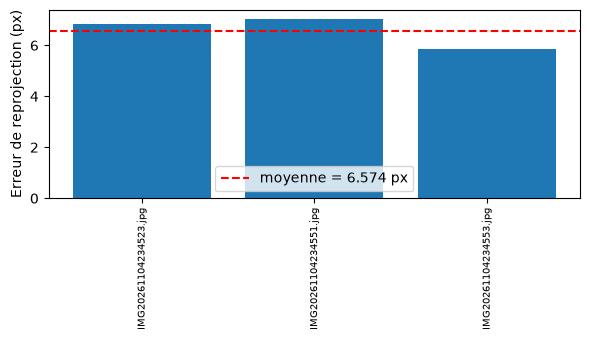

In [7]:
errors = []
for i in range(len(objpoints)):
    proj, _ = cv2.projectPoints(objpoints[i], rvecs[i], tvecs[i], K, dist)
    a = imgpoints[i].reshape(-1, 2)
    b = proj.reshape(-1, 2)
    errors.append(np.sqrt(np.mean(np.sum((a - b) ** 2, axis=1))))
errors = np.array(errors)

print(f"Erreur moyenne : {errors.mean():.4f} px")
for n, e in zip(used, errors):
    print(f"  {n:30s} {e:.4f} px")

plt.figure(figsize=(max(6, 0.4 * len(used)), 3.5))
plt.bar(range(len(errors)), errors)
plt.axhline(errors.mean(), color="r", ls="--", label=f"moyenne = {errors.mean():.3f} px")
plt.xticks(range(len(errors)), used, rotation=90, fontsize=7)
plt.ylabel("Erreur de reprojection (px)")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_RESULTS, "reprojection_error.png"), dpi=150)
plt.show()

## 5. Sauvegarde dans `results/calib.npz`

In [8]:
np.savez(
    os.path.join(OUT_RESULTS, "calib.npz"),
    K=K, dist=dist,
    rvecs=np.array(rvecs), tvecs=np.array(tvecs),
    rms=rms, errors=errors,
    image_size=np.array(image_size),
    pattern_size=np.array(PATTERN),
    square_size=SQUARE_MM,
    used_images=np.array(used),
)
# objpoints/imgpoints : listes (motif éventuellement tourné), sauvegardées en objet
np.save(os.path.join(OUT_RESULTS, "imgpoints.npy"), np.array(imgpoints, dtype=object), allow_pickle=True)
np.save(os.path.join(OUT_RESULTS, "objpoints.npy"), np.array(objpoints, dtype=object), allow_pickle=True)
print("Sauvegardé dans", OUT_RESULTS)
if rejected:
    print("Images rejetées :", rejected)

# data = np.load("results/calib.npz"); K, dist = data["K"], data["dist"]

Sauvegardé dans results
Images rejetées : ['IMG20261104234334.jpg', 'IMG20261104234342.jpg', 'IMG20261104234349.jpg', 'IMG20261104234353.jpg', 'IMG20261104234407.jpg', 'IMG20261104234409.jpg', 'IMG20261104234518.jpg', 'IMG20261104234521.jpg', 'IMG20261104234526.jpg', 'IMG20261104234532.jpg', 'IMG20261104234533.jpg', 'IMG20261104234536.jpg', 'IMG20261104234538.jpg', 'IMG20261104234540.jpg', 'IMG20261104234543.jpg', 'IMG20261104234546.jpg', 'IMG20261104234604.jpg', 'IMG20261104234607.jpg', 'IMG20261104234608.jpg', 'IMG20261104234620.jpg', 'IMG20261104234621.jpg', 'IMG20261104234625.jpg', 'IMG20261104234626.jpg', 'IMG20261104234628.jpg', 'IMG20261104234631.jpg', 'IMG20261104234634.jpg', 'IMG20261104234636.jpg', 'IMG20261104234641.jpg', 'IMG20261104234642.jpg', 'IMG20261104234644_01.jpg']


## 6. Correction de la distorsion (avant / après)
`alpha = 0` : l'image est recadrée pour supprimer les bandes noires. `alpha = 1` conserve tous les pixels.

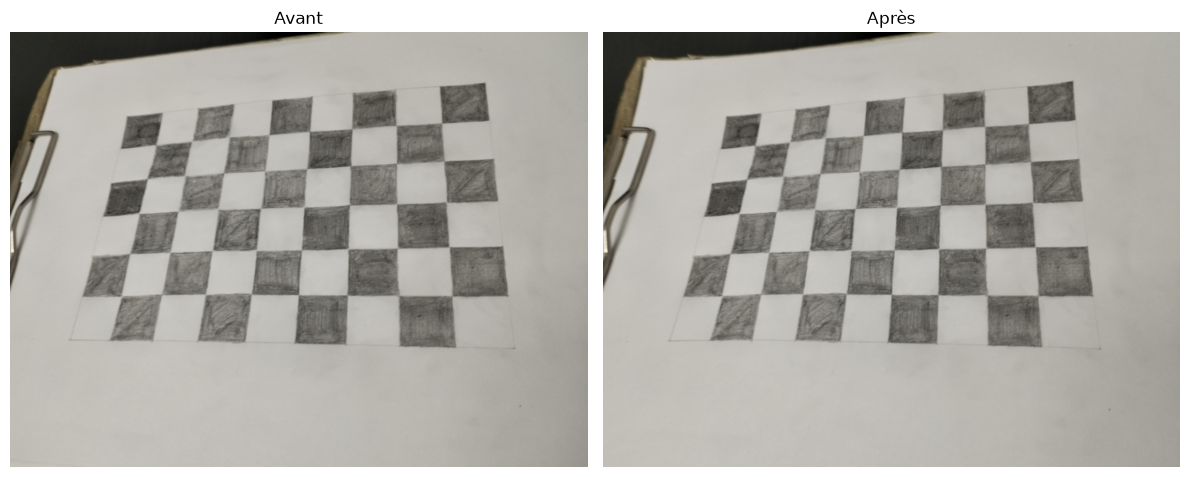

In [9]:
IDX = 0   # index de l'image dans `used`
img = cv2.imread(os.path.join(IMAGES_DIR, used[IDX]), READ_FLAGS)
h, w = img.shape[:2]
newK, roi = cv2.getOptimalNewCameraMatrix(K, dist, (w, h), 0, (w, h))
und = cv2.undistort(img, K, dist, None, newK)

def small(im, s=0.25):
    return cv2.cvtColor(cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(small(img)); ax[0].set_title("Avant"); ax[0].axis("off")
ax[1].imshow(small(und)); ax[1].set_title("Après"); ax[1].axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUT_RESULTS, "undistort_before_after.png"), dpi=150)
plt.show()